# 02 — Inverse indices

Express every other card and plan as a conversion into the baseline price.

The baseline is `GPU_BASE_PLAN`. For series \(k\) on date \(t\),

\[
i_{t,k} = P_{0,t} / P_{k,t}
\]

so \(i_{t,k} \times P_{k,t} = P_{0,t}\). Column 0 is not in the matrix. It is the vector of the baseline itself:

\[
I_t = P_{0,t} / P_{0,t_0}
\]

\(t_0\) is the first day of the continuous sample. The history has one print on 2026-04-01, then no quotes until 2026-05-17. The vector starts at \(t_0\) with value 1 and contains only dates where the baseline price exists, so it has no missing values.

A matrix cell is missing when that series has no price on that date. Those cells are left as NA. Results are stored under `outputs/baselines/<GPU_BASE_PLAN>/02_inverse/`. A later run for the same baseline rewrites a row only when the panel price behind it changed.


In [1]:
import sys

import matplotlib.pyplot as plt
import pandas as pd

from icx.indices import load_matrix, load_vector, matrix_with_gaps, sync_inverse_indices
from icx.panel import load_price_panel
from icx.runtime import require_project_venv
from icx.store import Decision, open_store

ROOT = require_project_venv()
layout = open_store(ROOT)
baseline = layout.baseline
print(f"Project:  {ROOT}")
print(f"Python:   {sys.executable}")
print(f"Baseline: {baseline.key}")


Project:  /home/neoabs/src/gka/ICX
Python:   /home/neoabs/src/gka/ICX/.venv/bin/python
Baseline: nvidia-h100__ON_DEMAND


In [2]:
vector_result, matrix_result = sync_inverse_indices(layout)
vector = vector_result.frame
matrix = matrix_result.frame
print(f"Vector build:  {vector_result.decision.value}  rows={len(vector):,}  upserted={vector_result.rows_upserted}")
print(f"Matrix build:  {matrix_result.decision.value}  rows={len(matrix):,}  upserted={matrix_result.rows_upserted}")

again_vector, again_matrix = sync_inverse_indices(layout)
print(f"Second vector: {again_vector.decision.value}")
print(f"Second matrix: {again_matrix.decision.value}")
if again_vector.decision is not Decision.SKIP or again_matrix.decision is not Decision.SKIP:
    raise RuntimeError("Unchanged panel should reuse the stored indices.")


Vector build:  skip  rows=132  upserted=0
Matrix build:  skip  rows=28,605  upserted=0
Second vector: skip
Second matrix: skip


In [3]:
base_date = str(vector["base_date"].iloc[0])
print(f"Base date: {base_date}")
print(f"Vector: {vector['date'].iloc[0]} → {vector['date'].iloc[-1]} ({len(vector)} dates)")
if vector["index_value"].isna().any():
    raise RuntimeError("Baseline vector contains a missing index.")
if float(vector["index_value"].iloc[0]) != 1.0 or str(vector["date"].iloc[0]) != base_date:
    raise RuntimeError("Vector does not start at 1 on the base date.")

gap = (matrix["index_value"] * matrix["price"] - matrix["base_price"]).abs()
print(f"Largest |i * P_k - P_0|: {gap.max():.3e}")
if gap.max() > 1e-4:
    raise RuntimeError("Inverse index does not recover the baseline price.")

panel = load_price_panel(layout)
wide = matrix_with_gaps(panel, vector, matrix, baseline.key)
missing = wide.isna().mean()
print(f"Matrix: {wide.shape[0]} dates × {wide.shape[1]} other series")
print(f"Share of cells that are NA: {missing.mean():.1%}")
print()
print(vector[["date", "price", "index_value"]].head(3).to_string(index=False))
print("...")
print(vector[["date", "price", "index_value"]].tail(3).to_string(index=False))


Base date: 2026-05-17
Vector: 2026-05-17 → 2026-09-25 (132 dates)
Largest |i * P_k - P_0|: 1.280e-07
Matrix: 132 dates × 273 other series
Share of cells that are NA: 20.6%

      date  price  index_value
2026-05-17  2.930     1.000000
2026-05-18  2.930     1.000000
2026-05-19  2.935     1.001706
...
      date  price  index_value
2026-09-23   3.20     1.092150
2026-09-24   3.20     1.092150
2026-09-25   3.25     1.109215


Other plans of the baseline card
series
nvidia-h100__CUSTOM         0.007576
nvidia-h100__RESERVATION    0.000000
nvidia-h100__SPOT           0.000000


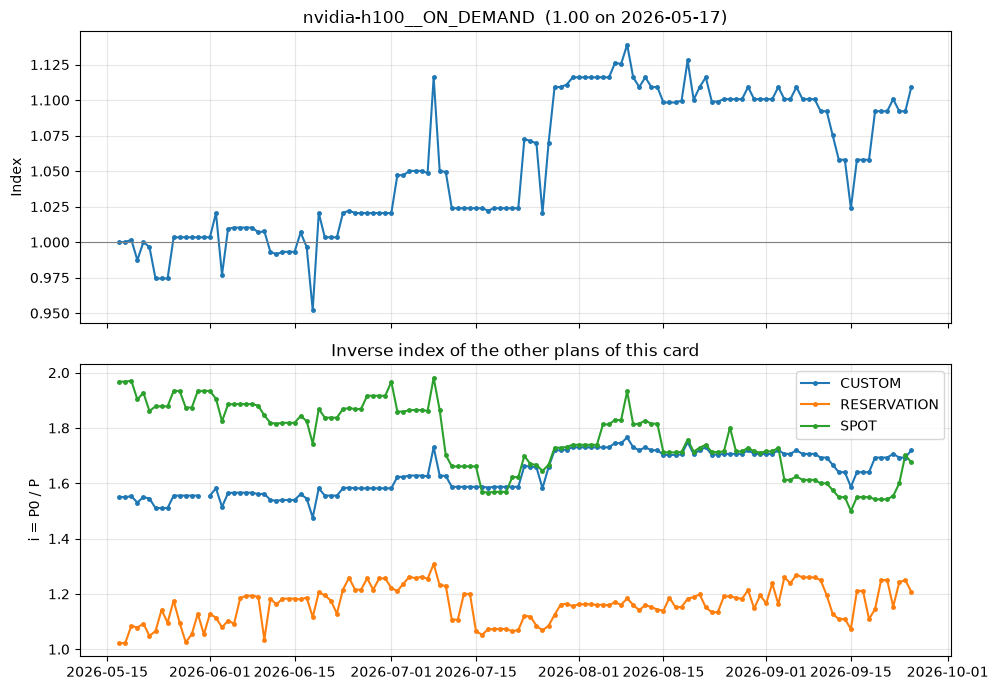

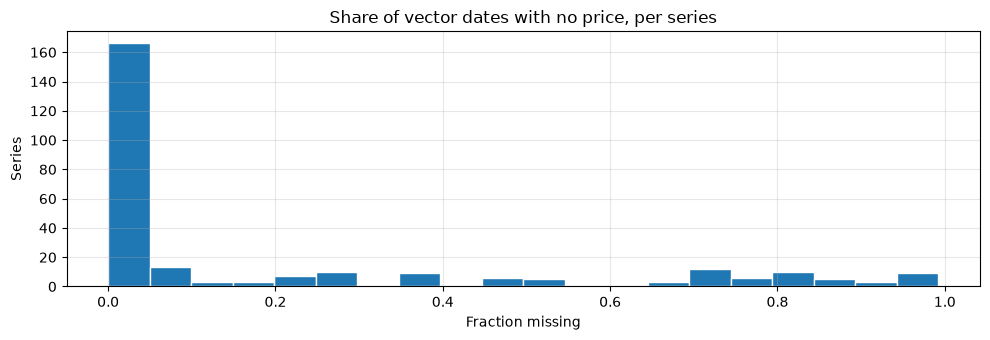

In [4]:
same_card = sorted(series for series in wide.columns if series.startswith(baseline.gpu_id + "__"))
print("Other plans of the baseline card")
print(missing.loc[same_card].rename("na_share").to_string())

def with_gaps(dates: pd.Series, values: pd.Series) -> pd.DataFrame:
    frame = pd.DataFrame({"date": pd.to_datetime(dates), "value": values}).dropna(subset=["date"])
    frame = frame.sort_values("date")
    rows = []
    previous = None
    for row in frame.itertuples(index=False):
        if previous is not None and (row.date - previous).days > 1:
            rows.append({"date": previous + pd.Timedelta(days=1), "value": float("nan")})
        rows.append({"date": row.date, "value": row.value})
        previous = row.date
    return pd.DataFrame(rows)

fig, axes = plt.subplots(2, 1, figsize=(10, 7), sharex=True)
base_line = with_gaps(vector["date"], vector["index_value"])
axes[0].plot(base_line["date"], base_line["value"], color="tab:blue", marker="o", ms=2.5)
axes[0].axhline(1.0, color="gray", lw=0.8)
axes[0].set_title(f"{baseline.key}  (1.00 on {base_date})")
axes[0].set_ylabel("Index")
axes[0].grid(True, alpha=0.3)

for series in same_card:
    column = wide[series]
    line = with_gaps(column.index, column.to_numpy())
    axes[1].plot(line["date"], line["value"], marker="o", ms=2.5, label=series.split("__", 1)[1])
axes[1].set_title("Inverse index of the other plans of this card")
axes[1].set_ylabel("i = P0 / P")
axes[1].legend()
axes[1].grid(True, alpha=0.3)
fig.tight_layout()
plt.show()

fig, axis = plt.subplots(figsize=(10, 3.5))
axis.hist(missing, bins=20, color="tab:blue", edgecolor="white")
axis.set_title("Share of vector dates with no price, per series")
axis.set_xlabel("Fraction missing")
axis.set_ylabel("Series")
axis.grid(True, alpha=0.3)
fig.tight_layout()
plt.show()
